# Detección temprana de DDoS por ventana de tiempo

Este cuaderno decide, **segundo a segundo**, si la red está bajo ataque y de
qué tipo. Es el paso de *clasificar flujos ya terminados* a *detectar mientras
pasa*.

Entrada: `data/processed/ventanas/ventanas.csv`, que arma
`scripts/mininet/build_windows.py` a partir de los contadores del portal
(`*_interno.csv`) y la telemetría OpenFlow del controlador (`*_sdn.csv`).

Evaluación honesta:

- **Validación cruzada por corrida** (leave-one-run-out) si hay varias
  corridas: cada corrida se usa una vez como prueba y el resto entrena. Se
  reporta **media ± desviación**. Con una sola corrida cae a una partición
  temporal 70/30 (el primer 70 % de cada escenario entrena, el final prueba).
- **Ablación de features**: solo-red vs. solo-SDN vs. todas, para ver cuánto
  aporta de verdad la vista SDN.
- **Comparación de modelos**: bosque aleatorio, gradient boosting y regresión
  logística.
- Métricas operativas: F1 macro y binario, tasa de falsos positivos sobre
  benigno, y tiempo hasta la primera alarma.

> El script equivalente, sin gráficos, es `notebooks/deteccion_ventanas.py`.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score, recall_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
if not (ROOT / "data" / "processed").is_dir():
    ROOT = ROOT.parent
DATA = ROOT / "data" / "processed" / "ventanas" / "ventanas.csv"

assert DATA.is_file(), (
    "Falta %s.\nCorre antes:  python3 scripts/mininet/build_windows.py" % DATA
)

REF_FIELDS = ["timestamp", "elapsed_s", "scenario", "run"]
ORDEN = ["BENIGN", "httpflood", "icmpflood", "slowloris", "synflood"]

df = pd.read_csv(DATA)
print("Ventanas:", len(df))
print("Corridas:", sorted(df["run"].unique()))
print()
print(df["Label"].value_counts())


Ventanas: 2960
Corridas: ['r01', 'r02', 'r03', 'r04', 'r05']

Label
BENIGN       600
httpflood    600
icmpflood    600
synflood     600
slowloris    560
Name: count, dtype: int64


## Balance de clases y señal cruda

Cuántas ventanas hay por clase, y una mirada rápida a dos señales que separan
los escenarios sin modelo alguno.


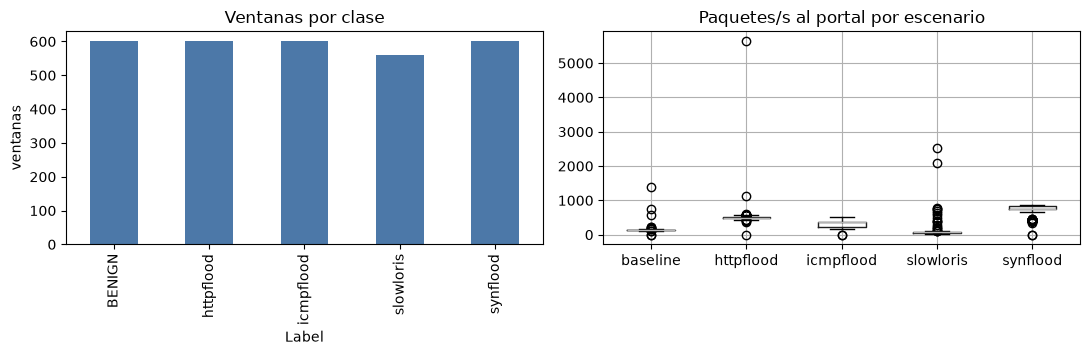

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
df["Label"].value_counts().reindex(ORDEN).plot.bar(ax=ax1, color="#4C78A8")
ax1.set_title("Ventanas por clase")
ax1.set_ylabel("ventanas")
df.boxplot(column="server_rx_pps", by="scenario", ax=ax2)
ax2.set_title("Paquetes/s al portal por escenario")
ax2.set_xlabel("")
plt.suptitle("")
plt.tight_layout()
plt.show()


## Features, grupos y partición

Se descartan las columnas de referencia (tiempo, escenario, corrida). Las
features se agrupan en **red** (contadores del portal y derivadas) y **sdn**
(telemetría del controlador) para la ablación.


In [3]:
def feature_cols(df):
    return [c for c in df.columns if c not in REF_FIELDS + ["Label"]]


def grupos_de_features(cols):
    sdn = [c for c in cols if c.startswith("sdn_")]
    red = [c for c in cols if not c.startswith("sdn_")]
    g = {"red": red, "todas": cols}
    if sdn:
        g["sdn"] = sdn
    return g


def matriz_numerica(df, cols):
    X = df[cols].apply(pd.to_numeric, errors="coerce")
    return X.replace([np.inf, -np.inf], np.nan).fillna(0)


def folds(df, train_fraction=0.70):
    runs = sorted(df["run"].unique())
    if len(runs) >= 2:
        salida = []
        for holdout in runs:
            tr = sorted(df.index[df["run"] != holdout])
            te = sorted(df.index[df["run"] == holdout])
            if df.loc[tr, "Label"].nunique() > 1 and te:
                salida.append((tr, te, holdout))
        return salida, "leave-one-run-out (%d corridas)" % len(runs)
    tr, te = [], []
    for _s, grupo in df.groupby("scenario", sort=False):
        grupo = grupo.sort_values("timestamp")
        corte = int(len(grupo) * train_fraction)
        tr.extend(grupo.index[:corte])
        te.extend(grupo.index[corte:])
    return [(sorted(tr), sorted(te), "temporal")], "particion temporal 70/30 (1 corrida)"


def modelos():
    return {
        "bosque": RandomForestClassifier(
            n_estimators=200, class_weight="balanced_subsample",
            random_state=42, n_jobs=-1),
        "gradient_boosting": GradientBoostingClassifier(random_state=42),
        "regresion_logistica": make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=2000, class_weight="balanced")),
    }


cols = feature_cols(df)
grupos = grupos_de_features(cols)
particiones, modo = folds(df)
y = df["Label"]
hay_sdn = bool(df.get("sdn_flows_total", pd.Series([0])).abs().sum()) if "sdn_flows_total" in df else False
print("Partición:", modo, "|", len(particiones), "fold(s)")
print("Features: red=%d  sdn=%d  todas=%d" % (len(grupos["red"]), len(grupos.get("sdn", [])), len(cols)))
if not hay_sdn:
    print("AVISO: columnas sdn_* en 0 (datos del controlador viejo). La ablación de SDN dará 0.")


Partición: leave-one-run-out (5 corridas) | 5 fold(s)
Features: red=12  sdn=14  todas=26


In [4]:
def evalua_fold(df, X, y, tr, te, model):
    vary = [c for c in X.columns if X.loc[tr, c].nunique() > 1]
    if not vary:
        return None
    model.fit(X.loc[tr, vary], y.loc[tr])
    pred = pd.Series(model.predict(X.loc[te, vary]), index=te)
    yt = y.loc[te]
    macro = f1_score(yt, pred, average="macro", zero_division=0)
    y_bin = np.where(yt == "BENIGN", "BENIGN", "ATAQUE")
    p_bin = np.where(pred == "BENIGN", "BENIGN", "ATAQUE")
    f1_bin = f1_score(y_bin, p_bin, average="macro", zero_division=0)
    benignas = (yt == "BENIGN").to_numpy()
    n_ben = int(benignas.sum())
    fp = int(((pred.to_numpy() != "BENIGN") & benignas).sum())
    fpr = fp / n_ben if n_ben else 0.0
    recalls = {c: recall_score(yt, pred, labels=[c], average="macro", zero_division=0)
               for c in ORDEN if (yt == c).any()}
    alarmas = {}
    for scenario, grupo in df.loc[te].groupby("scenario", sort=False):
        if scenario in ("BENIGN", "baseline"):
            continue
        g = grupo.sort_values("elapsed_s")
        base = int(g["elapsed_s"].iloc[0])
        a = None
        for idx in g.index:
            if pred.loc[idx] != "BENIGN":
                a = int(g.loc[idx, "elapsed_s"]) - base
                break
        alarmas[scenario] = a
    return {"macro": macro, "f1_bin": f1_bin, "fpr": fpr, "recalls": recalls,
            "alarmas": alarmas, "yt": yt, "pred": pred}


def corre_cv(df, y, cols, model_factory, particiones):
    Xm = matriz_numerica(df, cols)
    out = []
    for tr, te, _n in particiones:
        r = evalua_fold(df, Xm, y, tr, te, model_factory())
        if r is not None:
            out.append(r)
    return out


def ms(vals):
    return (float(np.mean(vals)), float(np.std(vals))) if vals else (float("nan"), float("nan"))


## Comparación de modelos

Con todas las features. El número que importa es el F1 macro (promedia las
cinco clases por igual, sin dejar que la clase grande domine).


In [5]:
filas = []
for nombre in modelos():
    res = corre_cv(df, y, grupos["todas"], lambda n=nombre: modelos()[n], particiones)
    mm, ms_ = ms([r["macro"] for r in res])
    bm, bs = ms([r["f1_bin"] for r in res])
    filas.append({"modelo": nombre, "F1_macro": mm, "F1_macro_std": ms_,
                  "F1_binario": bm, "F1_binario_std": bs})
tabla_modelos = pd.DataFrame(filas).set_index("modelo").round(3)
tabla_modelos


,F1_macro,F1_macro_std,F1_binario,F1_binario_std
modelo,,,,
bosque,0.999,0.001,1.000,0.000
gradient_boosting,0.999,0.001,1.000,0.000
regresion_logistica,0.997,0.004,0.999,0.001


## Ablación: ¿cuánto aporta el SDN?

Mismo modelo (bosque), cambiando solo el grupo de features. Si `todas` supera a
`red`, la telemetría del controlador está aportando.


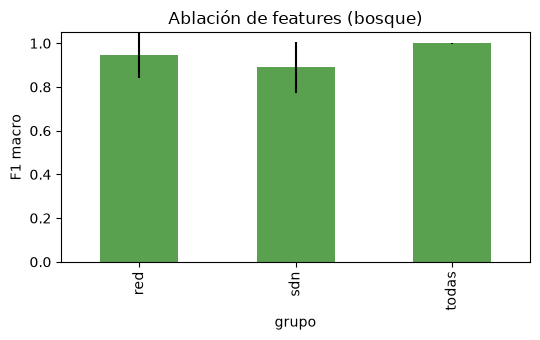

Aporte del SDN (todas - red): +0.054 de F1 macro


,F1_macro,std
grupo,,
red,0.945,0.104
sdn,0.890,0.117
todas,0.999,0.001


In [6]:
orden_grupos = [g for g in ("red", "sdn", "todas") if g in grupos]
filas = []
for g in orden_grupos:
    res = corre_cv(df, y, grupos[g], lambda: modelos()["bosque"], particiones)
    m, s = ms([r["macro"] for r in res])
    filas.append({"grupo": g, "F1_macro": m, "std": s})
tabla_ablacion = pd.DataFrame(filas).set_index("grupo").round(3)

fig, ax = plt.subplots(figsize=(5.5, 3.5))
tabla_ablacion["F1_macro"].plot.bar(yerr=tabla_ablacion["std"], ax=ax, color="#59A14F")
ax.set_ylim(0, 1.05)
ax.set_ylabel("F1 macro")
ax.set_title("Ablación de features (bosque)")
plt.tight_layout()
plt.show()

if "red" in tabla_ablacion.index and "todas" in tabla_ablacion.index:
    delta = tabla_ablacion.loc["todas", "F1_macro"] - tabla_ablacion.loc["red", "F1_macro"]
    print("Aporte del SDN (todas - red): %+.3f de F1 macro" % delta)
tabla_ablacion


## Detalle del bosque (todas las features)

Media ± desviación entre folds de las métricas operativas, recall por clase y
tiempo hasta la primera alarma.


In [7]:
res_rf = corre_cv(df, y, grupos["todas"], lambda: modelos()["bosque"], particiones)
mm, ms_ = ms([r["macro"] for r in res_rf])
bm, bs = ms([r["f1_bin"] for r in res_rf])
fm, fs = ms([r["fpr"] for r in res_rf])
print("F1 macro:   %.3f +/- %.3f" % (mm, ms_))
print("F1 binario: %.3f +/- %.3f" % (bm, bs))
print("Falsos positivos en benigno: %.1f%% +/- %.1f%%" % (100*fm, 100*fs))

rec = []
for c in ORDEN:
    vals = [r["recalls"][c] for r in res_rf if c in r["recalls"]]
    if vals:
        m, s = ms(vals)
        rec.append({"clase": c, "recall": m, "std": s})
display(pd.DataFrame(rec).set_index("clase").round(3))

lat = []
for c in ORDEN:
    if c == "BENIGN":
        continue
    vals = [r["alarmas"][c] for r in res_rf if c in r["alarmas"] and r["alarmas"][c] is not None]
    if vals:
        m, s = ms(vals)
        lat.append({"clase": c, "primera_alarma_s": m, "std": s})
print("\nTiempo hasta la primera alarma (s):")
display(pd.DataFrame(lat).set_index("clase").round(1))


F1 macro:   0.999 +/- 0.001
F1 binario: 1.000 +/- 0.000
Falsos positivos en benigno: 0.0% +/- 0.0%


,recall,std
clase,,
BENIGN,1.000,0.000
httpflood,1.000,0.000
icmpflood,0.998,0.003
slowloris,0.996,0.004
synflood,1.000,0.000



Tiempo hasta la primera alarma (s):


,primera_alarma_s,std
clase,,
httpflood,0.0,0.0
icmpflood,0.0,0.0
slowloris,0.0,0.0
synflood,0.0,0.0


## Matriz de confusión e importancia de features

La matriz junta las predicciones de todos los folds. Las importancias salen de
un bosque entrenado con todo el dataset (orientativo).


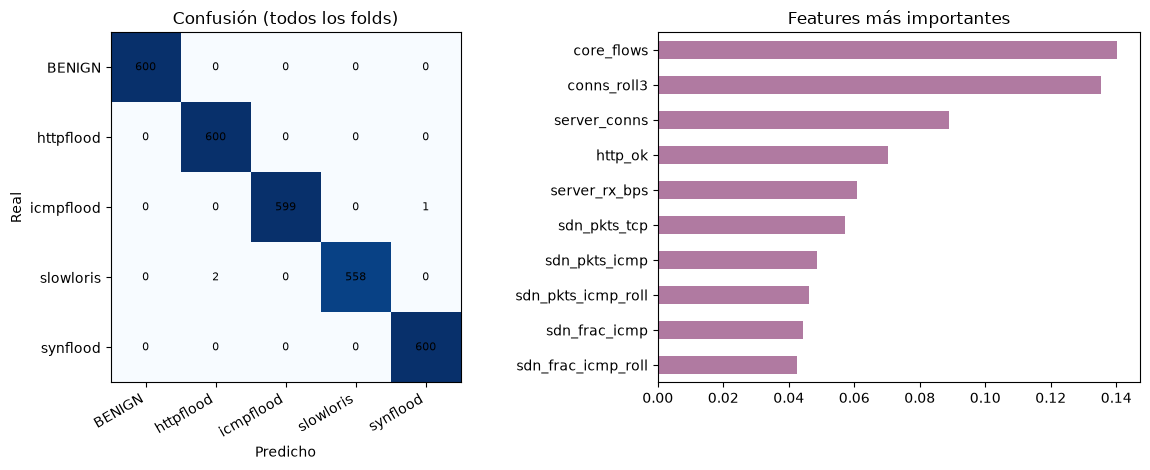

In [8]:
yt_all = pd.concat([r["yt"] for r in res_rf])
pred_all = pd.concat([r["pred"] for r in res_rf])
labels = [c for c in ORDEN if c in set(yt_all) or c in set(pred_all)]
mat = confusion_matrix(yt_all, pred_all, labels=labels)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
im = ax1.imshow(mat, cmap="Blues")
ax1.set_xticks(range(len(labels))); ax1.set_yticks(range(len(labels)))
ax1.set_xticklabels(labels, rotation=30, ha="right"); ax1.set_yticklabels(labels)
ax1.set_xlabel("Predicho"); ax1.set_ylabel("Real"); ax1.set_title("Confusión (todos los folds)")
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax1.text(j, i, str(mat[i, j]), ha="center", va="center", fontsize=8)

rf = modelos()["bosque"]
X_all = matriz_numerica(df, grupos["todas"])
vary = [c for c in X_all.columns if X_all[c].nunique() > 1]
rf.fit(X_all[vary], y)
imp = pd.Series(rf.feature_importances_, index=vary).sort_values(ascending=False).head(10)
imp.iloc[::-1].plot.barh(ax=ax2, color="#B07AA1")
ax2.set_title("Features más importantes")
plt.tight_layout()
plt.show()


## Lectura honesta

- Con **una sola corrida** la desviación es 0 y el F1 es optimista: los ataques
  sintéticos son muy distintos entre sí. Para afirmar algo hacen falta varias
  corridas (`bash scripts/docker/run_scenario.sh repeat N`) y reportar
  media ± desviación.
- La **ablación** dice si el SDN aporta sobre usar solo los contadores del
  portal. Si las columnas `sdn_*` están en 0, son datos del controlador viejo:
  recaptura con `flow_monitor_13`.
- Este detector puntúa ventanas ya capturadas (offline). Llevarlo **dentro de
  Ryu** para detección en vivo es el trabajo futuro.
